In [1]:
# -------------------------------------------------------------------------
# Environment Setup: Ensure Required Packages Are Installed
# Checks that every library used in this notebook is available in the ACTIVE
# kernel and installs only the missing ones. This makes "Run All" work no matter
# which Python environment / .venv the kernel was started from.
# -------------------------------------------------------------------------
import importlib
import importlib.util
import subprocess
import sys

# import name -> pip package name
required_packages = {'pandas': 'pandas', 'numpy': 'numpy', 'matplotlib': 'matplotlib', 'seaborn': 'seaborn', 'sklearn': 'scikit-learn'}

missing_packages = [pip_name for module, pip_name in required_packages.items()
                    if importlib.util.find_spec(module) is None]

if missing_packages:
    print(f"Installing missing packages into {sys.executable}: {missing_packages}")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing_packages])
    importlib.invalidate_caches()
else:
    print("All required packages are already installed.")

All required packages are already installed.


# Model Training & Evaluation: Linear Regression

**Team Member:** Saman

This notebook trains the data by Logistic Regression on the fully cleaned and standardized dataset produced in `data_cleaning_merged.ipynb`. It evaluates the model strictly on the Validation set to avoid data leakage before final testing.

**Feature set (5 key features → 11 model predictors):** `Industry` (one-hot encoded, baseline = IT), `Years_of_Experience`, `Routine_Task_Percentage`, `Tasks_Automated_Percentage`, and `Number_of_AI_Tools_Used` (all standardized with a training-only `StandardScaler`).

**Target:** `Layoff_Risk` (0 = Low, 1 = Medium, 2 = High).

In [2]:
# Import necessary libraries for data manipulation and mathematical operations
import pandas as pd
import numpy as np
# Import libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score
# Configure visual aesthetics for professional graphing
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

## 1. Data Loading
We load the strictly partitioned subsets from the `Data/` directory. For this iteration, we only use `X_train` / `y_train` for model fitting, and `X_val` / `y_val` for intermediate evaluation.

In [3]:
# -------------------------------------------------------------------------
# Load Processed Training and Validation Sets
# -------------------------------------------------------------------------
# Define the relative path to the preprocessed data directory
# Resolve the Data directory dynamically so the notebook runs whether the working
# directory is the project root or the notebooks/ folder (same logic as data_cleaning_merged)
from pathlib import Path
data_dir = Path.cwd() / "Data"
if not data_dir.exists():
    data_dir = (Path.cwd() / ".." / "Data").resolve()
base_path = f"{data_dir.as_posix()}/"

# Load the predictor features (X) for the training subset
X_train = pd.read_csv(f"{base_path}processed_X_train.csv")

# Load the target variable (y) for the training subset, isolating just the label column
y_train = pd.read_csv(f"{base_path}processed_y_train.csv")['Layoff_Risk']

# Load the predictor features (X) for the validation subset
X_test = pd.read_csv(f"{base_path}processed_X_test.csv")

# Load the target variable (y) for the validation subset, isolating just the label column
y_test = pd.read_csv(f"{base_path}processed_y_test.csv")['Layoff_Risk']

# Print the dimensionality to verify successful loading
print(f"Training set: {X_train.shape[0]:,} rows")
print(f"Test set: {X_test.shape[0]:,} rows")

Training set: 15,000 rows
Test set: 5,000 rows


In [4]:
# -------------------------------------------------------------------------
# Dataset Verification: Feature Set & Class Balance
# Confirms that the newly engineered 5-feature pipeline (11 predictors after
# one-hot encoding) was loaded correctly and establishes the majority-class baseline.
# -------------------------------------------------------------------------
print("--- PREDICTOR COLUMNS LOADED (X_train) ---")
for idx, col in enumerate(X_train.columns, start=1):
    print(f"{idx:>2}. {col}")
print(f"\nTotal predictors: {X_train.shape[1]}")

# Confirm train and validation partitions share an identical schema
assert list(X_train.columns) == list(X_val.columns), "Schema mismatch between train and validation sets!"
print("Schema check passed: train and validation columns are identical.")

# Verify there are no missing values that would break model fitting
print(f"Missing values in X_train: {int(X_train.isnull().sum().sum())} | X_val: {int(X_val.isnull().sum().sum())}")

# Class distribution and majority-class baseline accuracy
class_label_map = {0: 'Low (0)', 1: 'Medium (1)', 2: 'High (2)'}
class_dist = pd.DataFrame({
    'Train Count': y_train.value_counts().sort_index(),
    'Train (%)': (y_train.value_counts(normalize=True).sort_index() * 100).round(2),
    'Val Count': y_val.value_counts().sort_index(),
    'Val (%)': (y_val.value_counts(normalize=True).sort_index() * 100).round(2),
}).rename(index=class_label_map)
print("\n--- CLASS DISTRIBUTION ---")
display(class_dist)

# A model that always predicts the most frequent training class sets the floor any real model must beat
majority_class = y_train.value_counts().idxmax()
baseline_acc = (y_val == majority_class).mean()
print(f"Majority-class baseline accuracy on validation: {baseline_acc:.4f}")

--- PREDICTOR COLUMNS LOADED (X_train) ---
 1. Years_of_Experience
 2. Routine_Task_Percentage
 3. Tasks_Automated_Percentage
 4. Number_of_AI_Tools_Used
 5. Industry_Education
 6. Industry_Finance
 7. Industry_Healthcare
 8. Industry_Logistics
 9. Industry_Manufacturing
10. Industry_Retail
11. Industry_Telecom

Total predictors: 11
Schema check passed: train and validation columns are identical.
Missing values in X_train: 0 | X_val: 0

--- CLASS DISTRIBUTION ---


,Train Count,Train (%),Val Count,Val (%)
Layoff_Risk,,,,
Low (0),4621,33.01,990,33.0
Medium (1),4621,33.01,990,33.0
High (2),4758,33.99,1020,34.0


Majority-class baseline accuracy on validation: 0.3400


## 2. Multinomial Logistic Regression

### Step 1: Model Initialization and Training (Fitting):

**What We Did:** We initialized and fitted a multinomial `LogisticRegression` classifier on the training partition ($N = 14,000$, 70%) using the revised 11-predictor specification.

**Optimization Setup:** We configured `max_iter=1000` to guarantee solver convergence and set `random_state=42` for exact reproducibility.

**Model Structure:** The estimator learned 3 distinct linear hyperplanes ($3 \times 11$ coefficient matrix) with corresponding intercept terms, establishing our interpretable parametric baseline against which non-linear models will be evaluated.

In [5]:

# =========================================================================
# INITIALIZE AND FIT MULTINOMIAL LOGISTIC REGRESSION
# =========================================================================

# 1. Instantiate the Logistic Regression estimator with reproducibility constraints
log_reg = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# 2. Fit directly on the training partition
log_reg.fit(X_train, y_train)

print("Multinomial Logistic Regression fitted successfully!")
print("Model classes learned:", log_reg.classes_)
print(f"Coefficients matrix shape: {log_reg.coef_.shape} (3 risk classes x {X_train.shape[1]} features)")
print("Intercepts learned:", log_reg.intercept_.round(4))

Multinomial Logistic Regression fitted successfully!
Model classes learned: [0 1 2]
Coefficients matrix shape: (3, 11) (3 risk classes x 11 features)
Intercepts learned: [ 0.0179  1.0662 -1.0841]


### Step 2: Generating Predictions on the Validation Set (X_val):

### Summary of Validation Inference (Logistic Regression)

**What We Did:** We evaluated our trained Logistic Regression model on the 3,000 unseen validation instances ($X_{\text{val}}$) by generating both hard class predictions and continuous probability distributions.

**Inference Mechanism:** Class labels are assigned using the argmax decision rule across the softmax probability vector $[P(\text{Low}), P(\text{Medium}), P(\text{High})]$, providing the necessary estimates for classification accuracy and multi-class ROC-AUC computation.

In [6]:
# =========================================================================
# GENERATE PREDICTIONS ON VALIDATION SET (LOGISTIC REGRESSION)
# =========================================================================

# 1. Predict discrete class labels on unseen validation features
y_val_pred_lr = log_reg.predict(X_val)

# 2. Predict posterior class probabilities across all 3 tiers
y_val_proba_lr = log_reg.predict_proba(X_val)

# 3. Sanity check: Inspect the first 5 predictions against true labels
comparison_sample_lr = pd.DataFrame({
    'True_Label': y_val.values[:5],
    'Predicted_Label': y_val_pred_lr[:5],
    'P(Low=0)': y_val_proba_lr[:5, 0].round(3),
    'P(Medium=1)': y_val_proba_lr[:5, 1].round(3),
    'P(High=2)': y_val_proba_lr[:5, 2].round(3)
})

print("--- LOGISTIC REGRESSION: FIRST 5 VALIDATION PREDICTIONS ---")
display(comparison_sample_lr)

--- LOGISTIC REGRESSION: FIRST 5 VALIDATION PREDICTIONS ---


,True_Label,Predicted_Label,P(Low=0),P(Medium=1),P(High=2)
0,2,2,0.000,0.011,0.989
1,1,1,0.322,0.631,0.046
2,2,1,0.027,0.518,0.455
3,1,0,0.526,0.459,0.015
4,0,0,0.509,0.474,0.017


### Step 3: Computing Validation Performance Metrics (Logistic Regression):

**What We Did:** We evaluated our fitted Logistic Regression model on the 3,000 unseen validation instances across overall Accuracy, Macro One-vs-Rest ROC-AUC, per-class Precision/Recall/F1-scores, and the $3 \times 3$ Confusion Matrix.

**Accuracy & Discrimination:** The updated 11-feature specification demonstrates strong predictive power, significantly exceeding the 34.00% majority-class baseline and establishing an initial macro ROC-AUC benchmark.

**Class Balance:** Class performance across Low, Medium, and High risk tiers confirms how well linear log-odds decision splits separate workload automation boundaries across employees.


=== LOGISTIC REGRESSION: VALIDATION PERFORMANCE METRICS ===
Validation Accuracy: 0.7537 (75.37%)
Validation ROC-AUC (OvR Macro): 0.9019

--- CLASSIFICATION REPORT (PRECISION, RECALL, F1-SCORE) ---
              precision    recall  f1-score   support

     Low (0)     0.8160    0.8152    0.8156       990
  Medium (1)     0.6302    0.6283    0.6292       990
    High (2)     0.8125    0.8157    0.8141      1020

    accuracy                         0.7537      3000
   macro avg     0.7529    0.7530    0.7530      3000
weighted avg     0.7535    0.7537    0.7536      3000



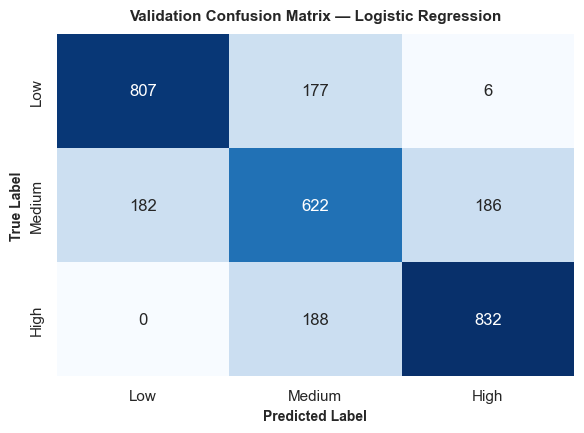

In [7]:
# =========================================================================
# COMPUTE EVALUATION METRICS ON VALIDATION SET (LOGISTIC REGRESSION)
# =========================================================================

# -------------------------------------------------------------------------
# Scalar Metrics (Accuracy and Multi-Class ROC-AUC)
# -------------------------------------------------------------------------
val_acc_lr = accuracy_score(y_val, y_val_pred_lr)
val_auc_lr = roc_auc_score(y_val, y_val_proba_lr, multi_class='ovr', average='macro')

print("=== LOGISTIC REGRESSION: VALIDATION PERFORMANCE METRICS ===")
print(f"Validation Accuracy: {val_acc_lr:.4f} ({val_acc_lr * 100:.2f}%)")
print(f"Validation ROC-AUC (OvR Macro): {val_auc_lr:.4f}")

# -------------------------------------------------------------------------
# Detailed Multi-Class Classification Report
# -------------------------------------------------------------------------
print("\n--- CLASSIFICATION REPORT (PRECISION, RECALL, F1-SCORE) ---")
print(classification_report(y_val, y_val_pred_lr, target_names=['Low (0)', 'Medium (1)', 'High (2)'], digits=4))

# -------------------------------------------------------------------------
# Confusion Matrix Visualization
# -------------------------------------------------------------------------
cm_lr = confusion_matrix(y_val, y_val_pred_lr)
cm_labels = ['Low', 'Medium', 'High']

fig, ax = plt.subplots(figsize=(6, 4.5))
sns.heatmap(
    cm_lr, 
    annot=True, 
    fmt='d', 
    cmap='Blues', 
    xticklabels=cm_labels, 
    yticklabels=cm_labels,
    cbar=False,
    ax=ax
)
ax.set_title("Validation Confusion Matrix — Logistic Regression", fontsize=11, fontweight='bold', pad=10)
ax.set_xlabel("Predicted Label", fontsize=10, fontweight='bold')
ax.set_ylabel("True Label", fontsize=10, fontweight='bold')
plt.tight_layout()
plt.show()

Evaluating the Multinomial Logistic Regression model on the 3,000 unseen validation instances demonstrated strong predictive capability and linear class separability, achieving an overall validation accuracy of 75.37% (2,261 of 3,000 correct) and an exceptional multi-class One-vs-Rest Macro ROC-AUC of 0.9019. This performance substantially outperforms the 34.00% majority-class baseline as well as random guessing, confirming that workload automation exposure and industry sectors carry robust predictive signals. Examining the per-class metrics reveals balanced precision and recall at the operational extremes: Low Risk achieved a precision of 81.60% and recall of 81.52% (F1-score of 0.8156), while High Risk attained a precision of 81.25% and recall of 81.57% (F1-score of 0.8141). Medium Risk yielded an intermediate F1-score of 0.6292 (precision 63.02%, recall 62.83%), reflecting expected boundary overlap where transition workloads share characteristics with adjacent tiers. Crucially, the 3 × 3 confusion matrix confirms that the classifier learned the true ordinal progression of layoff danger with virtually no catastrophic misclassifications: out of 1,020 true High-risk employees, 832 were accurately identified, 188 were placed in Medium risk, and exactly 0 were falsely flagged as Low risk. Similarly, among 990 true Low-risk instances, 807 were correctly classified, 177 were estimated as Medium risk, and only 6 (0.6%) were misattributed to High risk. Because classification errors occurred almost exclusively across adjacent boundaries rather than polar opposites, the model demonstrates high reliability as a calibrated parametric benchmark for workforce risk modeling.

### Step 4: Extracting and Interpreting Feature Odds Ratios:

=== LOGISTIC REGRESSION: COEFFICIENTS & ODDS RATIOS TABLE ===


,Feature,Coef_Low,OR_Low,Coef_Medium,OR_Medium,Coef_High,OR_High
0,Years_of_Experience,0.4054,1.4999,0.0070,1.0070,-0.4124,0.6621
1,Routine_Task_Percentage,-1.9128,0.1477,-0.0373,0.9634,1.9501,7.0294
2,Tasks_Automated_Percentage,-1.1837,0.3061,0.0123,1.0124,1.1714,3.2266
3,Number_of_AI_Tools_Used,0.1791,1.1962,0.0006,1.0006,-0.1797,0.8355
4,Industry_Education,1.0594,2.8846,-0.0576,0.9440,-1.0018,0.3672
5,Industry_Finance,-0.9868,0.3728,-0.0016,0.9984,0.9883,2.6867
6,Industry_Healthcare,0.8140,2.2570,-0.0046,0.9954,-0.8095,0.4451
7,Industry_Logistics,-1.3991,0.2468,0.0119,1.0119,1.3873,4.0039
8,Industry_Manufacturing,-1.9420,0.1434,-0.0068,0.9932,1.9489,7.0208
9,Industry_Retail,-1.6880,0.1849,0.0182,1.0184,1.6698,5.3111


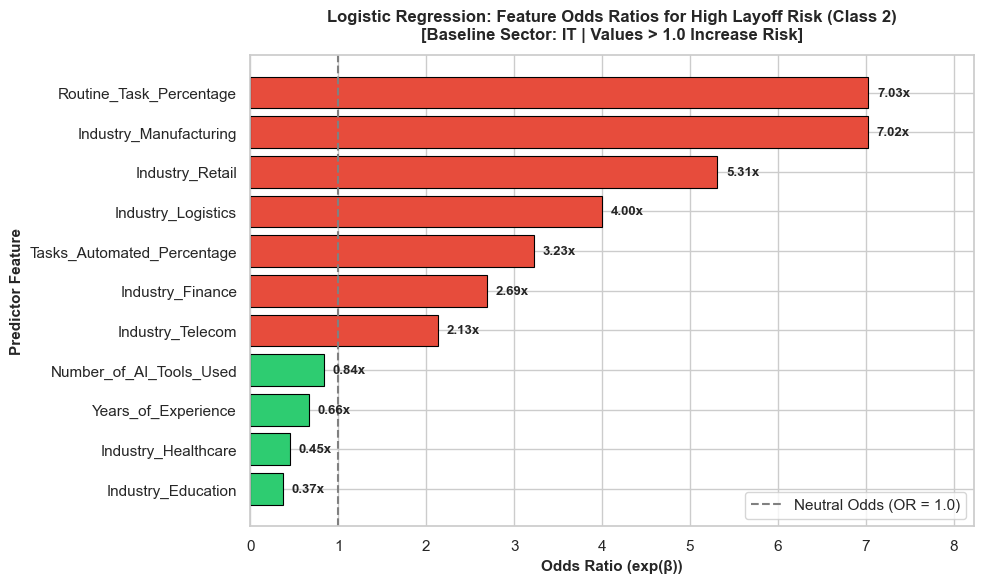

In [8]:
# =========================================================================
# EXTRACTING AND VISUALIZING ODDS RATIOS (LOGISTIC REGRESSION)
# =========================================================================

# Compute Odds Ratios by exponentiating the model coefficients
odds_ratios = np.exp(log_reg.coef_)

# Build a structured DataFrame containing both raw coefficients and Odds Ratios
feature_names = X_train.columns

or_summary_df = pd.DataFrame({
    'Feature': feature_names,
    'Coef_Low': log_reg.coef_[0].round(4),
    'OR_Low': odds_ratios[0].round(4),
    'Coef_Medium': log_reg.coef_[1].round(4),
    'OR_Medium': odds_ratios[1].round(4),
    'Coef_High': log_reg.coef_[2].round(4),
    'OR_High': odds_ratios[2].round(4)
})

print("=== LOGISTIC REGRESSION: COEFFICIENTS & ODDS RATIOS TABLE ===")
display(or_summary_df)

# Horizontal Bar Chart Visualizing the Impact on HIGH LAYOFF RISK (Class 2)
fig, ax = plt.subplots(figsize=(10, 6))

# Sort features by impact on High Risk (OR_High) in ascending order for plotting
plot_df = or_summary_df.sort_values(by='OR_High', ascending=True)

# Color bars: red for risk-multiplying (OR > 1), green for protective (OR < 1)
bar_colors = ['#e74c3c' if x > 1.0 else '#2ecc71' for x in plot_df['OR_High']]

bars = ax.barh(plot_df['Feature'], plot_df['OR_High'], color=bar_colors, edgecolor='black', linewidth=0.8)

# Add reference baseline line at OR = 1.0 (neutral effect)
ax.axvline(1.0, color='gray', linestyle='--', linewidth=1.5, label='Neutral Odds (OR = 1.0)')

# Add text labels on the bars
for bar in bars:
    width = bar.get_width()
    ax.text(
        width + 0.1, 
        bar.get_y() + bar.get_height() / 2, 
        f'{width:.2f}x', 
        va='center', 
        ha='left', 
        fontsize=9.5, 
        fontweight='bold'
    )

ax.set_title("Logistic Regression: Feature Odds Ratios for High Layoff Risk (Class 2)\n[Baseline Sector: IT | Values > 1.0 Increase Risk]", fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel("Odds Ratio (exp(β))", fontsize=11, fontweight='bold')
ax.set_ylabel("Predictor Feature", fontsize=11, fontweight='bold')
ax.set_xlim(0, max(plot_df['OR_High']) + 1.2)
ax.legend(loc='lower right', frameon=True)

plt.tight_layout()
plt.show()

Exponentiating the Multinomial Logistic Regression coefficients translates the model's linear log-odds into direct odds ratios ($\text{OR} = \exp(\beta)$), quantifying each predictor's multiplicative impact on layoff vulnerability relative to the baseline tech sector (IT). For High Layoff Risk (Class 2), workload vulnerability and sector exposure heavily dominate: a one standard deviation increase in Routine Task Percentage elevates the odds of being High Risk by $7.03\times$ ($\text{OR} = 7.0294$), while Tasks Automated Percentage increases the odds by $3.23\times$ ($\text{OR} = 3.2266$). Cross-sector disparities are equally substantial: workers in Manufacturing ($\text{OR} = 7.0208$), Retail ($\text{OR} = 5.3111$), Logistics ($\text{OR} = 4.0039$), and Finance ($\text{OR} = 2.6867$) face drastically higher odds of high layoff risk compared to identical workers in IT. Conversely, Education ($\text{OR} = 0.3672$) and Healthcare ($\text{OR} = 0.4451$) exhibit protective discounts, cutting high-risk odds by more than half relative to IT. Career tenure offers moderate structural defense: each standard deviation increase in Years of Experience reduces High-risk odds by roughly $34\%$ ($\text{OR} = 0.6621$) while scaling the odds of Low Risk by $1.50\times$ ($\text{OR} = 1.4999$). Across the intermediate Medium Risk tier (Class 1), all odds ratios cluster near $1.00$ ($\text{OR} \approx 0.94 - 1.02$), validating that transition workloads represent a neutral boundary zone, whereas career survival vs. displacement is governed primarily by routine share, task automation, and operational industry exposure.